# [2/3] Rekomendasi Destinasi Wisata Sadar-Musim: **E5 + Cosine Similarity**

Seri notebook *content-based filtering* (data, query, qrels, seed, dan metrik **identik** di ketiganya):
**[1] BGE-M3 + cosine** · **[2] E5 + cosine** · **[3] (BGE-M3 + E5) adaptive fusion + cosine** (sistem usulan).

Notebook ini adalah **sistem pembanding model tunggal**: E5 (`multilingual-e5-large`) tanpa digabung dengan BGE-M3 — baseline utama untuk mengukur kontribusi adaptive fusion.

**Cara kerja (content-based):**
1. Profil destinasi = kumpulan embedding ulasannya (`intfloat/multilingual-e5-large`).
2. Query pengguna di-*embed* dengan model yang sama dengan prefiks `query: ` (ulasan diberi prefiks `passage: `).
3. Skor ulasan = **cosine similarity**(query, ulasan); skor destinasi $s(d)$ = rata-rata top-$m$ skor ulasannya ($m=5$).
4. Destinasi diurutkan menurut $s(d)$ → top-K rekomendasi.

**Google Colab:** *Runtime → Change runtime type → **T4 GPU***; simpan `koreksi_dataset.xlsx` di `MyDrive/Rekomendasi_Wisata/` (atau ubah `DRIVE_DIR` di sel setup), lalu *Runtime → Run all*. Embedding di-*cache* di Drive dan dipakai bersama notebook 1–3; hasil tersimpan di `MyDrive/Rekomendasi_Wisata/output_e5/`.

In [2]:
# ── 0. Setup lingkungan (Google Colab) ──
import os, sys, subprocess

DRIVE_DIR = '/content/drive/MyDrive/Colab Notebooks/SysRec/'   # folder kerja di Google Drive (ubah bila perlu)
DATA_NAME = 'koreksi_dataset.xlsx'                          # dataset ulasan terkoreksi

IS_COLAB = 'google.colab' in sys.modules
MOCK     = os.environ.get('MOCK_ENCODER', '0') == '1'      # 1 = uji alur kode tanpa model besar (CPU)

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ftfy', 'sentence-transformers'], check=False)
    WORK_DIR = DRIVE_DIR
else:
    WORK_DIR = os.environ.get('WORK_DIR', '.')
os.makedirs(WORK_DIR, exist_ok=True)
print('Folder kerja:', WORK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder kerja: /content/drive/MyDrive/Colab Notebooks/SysRec/


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import re, glob, json, math, time, random, copy, hashlib, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import cohen_kappa_score

try:
    from ftfy import fix_text          # memperbaiki mojibake (mis. "ðŸ˜­" → "😭")
except ImportError:
    fix_text = lambda s: s

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)

In [5]:
# ── 1. Konfigurasi eksperimen ──
CFG = dict(
    seed            = 42,
    bge_model       = 'BAAI/bge-m3',
    e5_model        = 'intfloat/multilingual-e5-large',
    e5_query_prefix = 'query: ',
    e5_doc_prefix   = 'passage: ',
    max_len         = 256,
    batch_size      = 64,
    topm            = 5,      # skor destinasi = rata-rata top-m skor ulasannya
    min_words       = 3,      # ulasan < 3 kata dibuang (tidak informatif)
    n_known_item    = 4000,   # jumlah query Protokol B
    k               = 10,
    tau             = 0.5,    # temperatur ListNet
    gate_hidden     = 32,
    gate_dropout    = 0.1,
    gate_lr         = 3e-3,
    gate_wd         = 1e-3,
    gate_epochs     = 400,
    gate_patience   = 40,
    ctx_dropout     = 0.2,    # peluang konteks musim disembunyikan saat latih
    gate_seeds      = [0, 1, 2],
    pca_dim         = 16,
    n_folds         = 5,
    lam_grid        = np.round(np.linspace(0, 1, 21), 2),
    n_boot          = 1000,
)
if MOCK:
    CFG.update(n_known_item=500, gate_epochs=150, gate_seeds=[0], mock_cap=40)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE  = torch.float16 if DEVICE == 'cuda' else torch.float32

OUT_DIR = os.environ.get('OUT_DIR', os.path.join(WORK_DIR, 'output_e5'))
CACHE   = os.path.join(WORK_DIR, 'cache_embeddings' + ('_mock' if MOCK else ''))   # dipakai bersama notebook 1–3
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(CACHE, exist_ok=True)

def find_data():
    cands = [os.environ.get('DATA_PATH', ''), os.path.join(WORK_DIR, DATA_NAME), os.path.join('/content', DATA_NAME), DATA_NAME]
    for p in cands:
        if p and os.path.exists(p):
            return p
    if IS_COLAB:   # belum ada di Drive → unggah manual, lalu disimpan ke folder kerja
        from google.colab import files
        print(f'{DATA_NAME} tidak ditemukan di {WORK_DIR}. Silakan unggah file tersebut:')
        up = files.upload()
        if DATA_NAME in up:
            dst = os.path.join(WORK_DIR, DATA_NAME)
            with open(dst, 'wb') as f:
                f.write(up[DATA_NAME])
            return dst
    raise FileNotFoundError(f'{DATA_NAME} tidak ditemukan (letakkan di {WORK_DIR})')

DATA_PATH = find_data()
if IS_COLAB and DEVICE != 'cuda':
    print('⚠️ GPU tidak aktif — pilih Runtime → Change runtime type → T4 GPU, lalu jalankan ulang.')
print('Device  :', DEVICE, '| MOCK :', MOCK)
print('Data    :', DATA_PATH)
print('Output  :', OUT_DIR)
print('Cache   :', CACHE)

Device  : cuda | MOCK : False
Data    : /content/drive/MyDrive/Colab Notebooks/SysRec/koreksi_dataset.xlsx
Output  : /content/drive/MyDrive/Colab Notebooks/SysRec/output_e5
Cache   : /content/drive/MyDrive/Colab Notebooks/SysRec/cache_embeddings


## 2. Data understanding & preparation
- **Dataset:** `koreksi_dataset.xlsx` (79.514 ulasan, 207 destinasi; kolom `id_destinasi, destinasi, rating, date, text_original, text_preprocessed, rekomendasi_cuaca, wisata`). Dataset ini adalah versi terkoreksi dari `Hasil_Mapping_Ulasan_Wisata.xlsx`: pada file lama, 84 dari 207 label `destinasi` (33.205 baris ulasan) tertempel pada kelompok ulasan yang salah (mis. kelompok "Sedudo" berisi ulasan Selecta) dan kategori `wisata` ikut bergeser. Nama dipulihkan secara deterministik dari urutan `id_destinasi` (identik dengan urutan nama mentah data asli) dan kategori diverifikasi ulang; teks, rating, tanggal, dan label musim tidak diubah. Rincian perubahan per destinasi ada di `koreksi_destinasi.xlsx`.
- Teks yang di-*embed* adalah `text_original` (model kontekstual tidak butuh stemming/stopword removal); hanya diperbaiki mojibake-nya dan dirapikan spasi.
- Ulasan < 3 kata dan duplikat (destinasi, teks) dibuang.
- Setiap destinasi memiliki satu kategori (`wisata`) dan satu label musim (`rekomendasi_cuaca`).

In [6]:
df_raw = pd.read_excel(DATA_PATH)
print('Ukuran awal :', df_raw.shape)

df = df_raw.copy()
df['wisata'] = df['wisata'].fillna('lainnya').astype(str).str.strip().str.lower()
df['text']   = (df['text_original'].fillna('').astype(str).map(fix_text)
                .str.replace(r'\s+', ' ', regex=True).str.strip())
df = df[df['text'].str.split().str.len() >= CFG['min_words']]
df = df.drop_duplicates(['destinasi', 'text'])

if MOCK:   # subsample per destinasi agar cepat di CPU
    df = df.sample(frac=1, random_state=CFG['seed'])
    df = df[df.groupby('destinasi').cumcount() < CFG['mock_cap']]

# ── Katalog destinasi ──
dest = (df.groupby('destinasi')
          .agg(wisata=('wisata', lambda s: s.mode().iat[0]),
               musim=('rekomendasi_cuaca', lambda s: s.mode().iat[0]),
               n_ulasan=('text', 'size'),
               rating_mean=('rating', 'mean'))
          .reset_index())
dest['cocok_hujan']   = dest['musim'].str.contains('Penghujan')
dest['cocok_kemarau'] = dest['musim'].str.contains('Kemarau')
D = len(dest)
dest_id = {d: i for i, d in enumerate(dest['destinasi'])}

# Urutkan ulasan per destinasi → setiap destinasi = satu segmen kontigu
df['did'] = df['destinasi'].map(dest_id)
df = df.sort_values('did', kind='stable').reset_index(drop=True)
OFFSETS = np.r_[0, np.cumsum(dest['n_ulasan'].values)]
N = len(df)

print(f'Ulasan bersih : {N:,} | Destinasi : {D}')
print(dest['musim'].value_counts().to_string())
dest.head()

Ukuran awal : (79514, 8)
Ulasan bersih : 67,283 | Destinasi : 207
musim
Kemarau & Penghujan    113
Kemarau                 94


,destinasi,wisata,musim,n_ulasan,rating_mean,cocok_hujan,cocok_kemarau
0,Air Dolo,air terjun,Kemarau & Penghujan,448,4.517857,True,True
1,Air Irenggolo,air terjun,Kemarau & Penghujan,246,4.548780,True,True
2,Air Panas Blawan,pemandian,Kemarau,108,4.583333,False,True
3,Air Terjun Coban Kromo,air terjun,Kemarau & Penghujan,33,3.787879,True,True
4,Air Terjun Jurug Warudongko,air terjun,Kemarau,7,5.000000,False,True


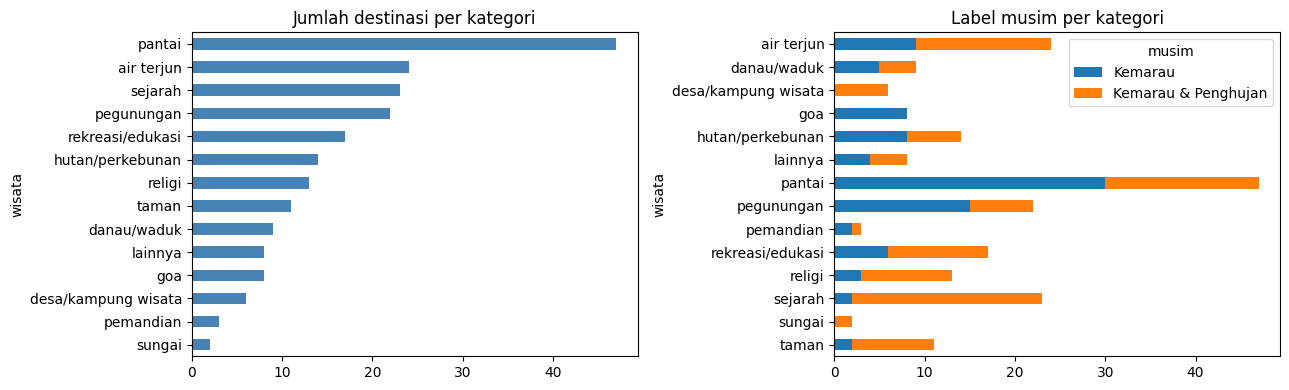

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dest['wisata'].value_counts().plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title('Jumlah destinasi per kategori'); ax[0].invert_yaxis()
pd.crosstab(dest['wisata'], dest['musim']).plot.barh(stacked=True, ax=ax[1])
ax[1].set_title('Label musim per kategori'); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_data.png', dpi=300); plt.show()

## 3. Test collection (ground truth)

Evaluasi lama (relevansi = rating ulasan, unit = ulasan) tidak mengukur **kecocokan destinasi dengan kebutuhan pengguna**. Karena itu dibangun dua protokol yang saling melengkapi:

**Protokol A — Query kebutuhan wisata bertingkat (graded qrels).** Query disusun dari *kategori* (13 kategori + 3 super-kategori: *wisata alam*, *budaya/religi*, *keluarga/buatan*) × *aspek* (8 aspek + tanpa aspek) × *musim* (hujan/kemarau) × *gaya bahasa* (formal, santai, Inggris). Relevansi destinasi $d$:

$$rel(q,d)=\mathbb{1}[\text{kategori cocok}]\cdot\mathbb{1}[\text{cocok musim}]\cdot\big(1+\mathbb{1}[\text{aspek kuat}]\big)\in\{0,1,2\}$$

"Aspek kuat" = proporsi ulasan destinasi yang memuat leksikon aspek berada di atas persentil-60 (sumber leksikal, independen dari kedua model embedding).

**Protokol B — Known-item (leave-one-review-out).** Satu ulasan dijadikan query, dikeluarkan dari indeks, dan destinasi asalnya adalah satu-satunya item relevan. Protokol ini tidak bergantung pada template/label buatan peneliti.

**Protokol C — Query uji skripsi.** Dua query yang dipakai pada skripsi *"Sistem Rekomendasi Pariwisata Jawa Timur Berbasis Seasonal Context-Aware Menggunakan BAAI General Embedding"* (Prasetyo, 2026 [7]):

| Kode | Query | Musim asli | Sumber |
|---|---|---|---|
| S1 | *Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.* | — | Tabel 3.1 |
| S2 | *Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmati udara segar.* | Kemarau | Bab 4 (`input_destinasi`) |

Setiap query diuji pada konteks musim **aslinya** dan pada **variasi konteks** (`none`, `kemarau`, `hujan`) dengan teks yang sama, sehingga terlihat apakah sistem menyesuaikan rekomendasi terhadap musim. Relevansi memakai aturan Protokol A: kategori (S1 → seluruh kategori alam, S2 → air terjun) × cocok musim × (1 + aspek kuat), dengan aspek S1 = {pemandangan, tenang} dan S2 = {sejuk, tenang, pemandangan}; "aspek kuat" = destinasi kuat pada ≥ separuh aspek query. Karena jumlah query sangat sedikit, Protokol C adalah **evaluasi studi kasus** (tidak untuk uji signifikansi) dan angka skripsi tidak dapat dibandingkan langsung karena skripsi memakai rating ulasan sebagai relevansi.

**Protokol D — Query uji berbasis literatur.** Desain query mengikuti praktik penelitian sejenis:

| Penelitian | Cara membangun query uji | Ground truth | Diadopsi sebagai |
|---|---|---|---|
| POINTREC (Afzali, Drzewiecki & Balog, 2021) [1] | 112 permintaan **naratif** nyata dari Reddit & Yahoo! Answers, dianotasi metadata (kategori, kendala, contoh POI) | *pooling* + crowdsourcing, relevansi bertingkat | **D1 — permintaan naratif** beranotasi metadata |
| TourismQA / LAMB (Contractor et al., 2021 [3]; Li, Tomko & Baldwin, 2024 [4]) | pertanyaan forum TripAdvisor; POI direpresentasikan oleh **ulasannya**; *dense bi-encoder* | POI pada jawaban forum | gaya pertanyaan forum di D1 |
| SynthTRIPs (Banerjee et al., 2025) [2] | query sintetis dari **persona** × filter (minat, **bulan**, budget, popularitas = jumlah ulasan, *off-peak*) dalam 4 tingkat kompleksitas; versi *vanilla* vs *persona* | filter terpenuhi pada *knowledge base* | **D2 — persona × kompleksitas** |
| Karlović et al. (2025) [5]; Trattner et al. (2018) [6] | query yang sama dievaluasi pada **konteks cuaca** berbeda | penilaian output / kunjungan nyata | konteks musim implisit melalui **bulan** perjalanan |

- **D1 (20 query naratif)** — gaya unggahan forum (bahasa Indonesia santai dan Inggris), tiap query dianotasi: kategori, bulan/musim, aspek, dan batasan popularitas.
- **D2 (persona × kompleksitas)** — 10 persona (keluarga, backpacker, fotografer, pasangan, pendaki, peziarah, guru, lansia, pekerja *healing*, turis asing) × 4 tingkat: *mudah* (kategori), *sedang* (+ bulan), *sulit* (+ aspek), *berkelanjutan* (+ belum ramai/*off-peak*) × 3 sampel; masing-masing dalam versi **vanilla** dan **persona** (pasangan berpasangan → uji ketahanan terhadap teks persona yang panjang).
- **Musim implisit:** query menyebut **bulan**, bukan kata "hujan/kemarau". Pemetaan (pendekatan pola monsun umum Jawa Timur, dapat disesuaikan): Nov–Mar = `hujan`, Mei–Sep = `kemarau`, April & Oktober = pancaroba → `none`.
- **Relevansi** = kategori cocok × cocok musim × cocok popularitas (bila diminta; tingkat popularitas = tertil jumlah ulasan, seperti SynthTRIPs) × (1 + aspek kuat).

### Daftar pustaka (sumber desain query uji, model, dan metode)

**Penelitian acuan query uji & ground truth**
1. Afzali, J., Drzewiecki, A. M., & Balog, K. (2021). POINTREC: A test collection for narrative-driven point of interest recommendation. In *Proceedings of the 44th International ACM SIGIR Conference on Research and Development in Information Retrieval (SIGIR '21)*. https://doi.org/10.1145/3404835.3463243
2. Banerjee, A., Satish, A., Aisyah, F. N., Wörndl, W., & Deldjoo, Y. (2025). SynthTRIPs: A knowledge-grounded framework for benchmark query generation for personalized tourism recommenders. In *Proceedings of the 48th International ACM SIGIR Conference (SIGIR '25)*. https://doi.org/10.1145/3726302.3730321
3. Contractor, D., Shah, K., Partap, A., Singla, P., & Mausam. (2021). Answering POI-recommendation questions using tourism reviews. In *Proceedings of the 30th ACM International Conference on Information and Knowledge Management (CIKM '21)*. https://doi.org/10.1145/3459637.3482320
4. Li, H., Tomko, M., & Baldwin, T. (2024). Location aware modular biencoder for tourism question answering. *arXiv:2401.02187*. https://arxiv.org/abs/2401.02187
5. Karlović, R., Rovis, M., Smajić, A., Sever, L., & Lorencin, I. (2025). Context-aware tourism recommendations using retrieval-augmented large language models and semantic re-ranking. *Electronics, 14*(22), 4448. https://doi.org/10.3390/electronics14224448
6. Trattner, C., Oberegger, A., Marinho, L., & Parra, D. (2018). Investigating the utility of the weather context for point of interest recommendations. *Information Technology & Tourism*. Preprint: https://christophtrattner.info/pubs/JITT_ctrattner.pdf
7. Prasetyo, S. G. (2026). *Sistem rekomendasi pariwisata Jawa Timur berbasis seasonal context-aware menggunakan BAAI General Embedding* [Skripsi, Program Studi Sistem Informasi, Universitas Trunojoyo Madura]. — sumber query uji Protokol C.

**Penelitian sejenis di Indonesia (pembanding)**

8. Hakim, S. P. R., Suharso, W., & Amiri, Y. I. A. (2026). Penerapan semantic embedding berbasis Sentence-BERT pada sistem rekomendasi pariwisata menggunakan content-based filtering. *Jurnal Penelitian Ilmiah Multidisiplin, 10*(7). https://oaj.jurnalhst.com/index.php/jpim/article/view/23975
9. Universitas Diponegoro. (2026). *Studi komparatif representasi teks TF-IDF dan IndoBERT berbasis content-based filtering menggunakan cosine similarity untuk rekomendasi destinasi wisata* [Skripsi; nama penulis lihat repositori]. https://eprints2.undip.ac.id/id/eprint/43830/

**Model embedding & metode**

10. Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D., & Liu, Z. (2024). BGE M3-Embedding: Multi-lingual, multi-functionality, multi-granularity text embeddings through self-knowledge distillation. *arXiv:2402.03216*. https://arxiv.org/abs/2402.03216
11. Wang, L., Yang, N., Huang, X., Yang, L., Majumder, R., & Wei, F. (2024). Multilingual E5 text embeddings: A technical report. *arXiv:2402.05672*. https://arxiv.org/abs/2402.05672
12. Järvelin, K., & Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems, 20*(4), 422–446. https://doi.org/10.1145/582415.582418
13. Cao, Z., Qin, T., Liu, T.-Y., Tsai, M.-F., & Li, H. (2007). Learning to rank: From pairwise approach to listwise approach (ListNet). In *Proceedings of the 24th International Conference on Machine Learning (ICML '07)*. https://doi.org/10.1145/1273496.1273513
14. Cormack, G. V., Clarke, C. L. A., & Büttcher, S. (2009). Reciprocal rank fusion outperforms Condorcet and individual rank learning methods. In *Proceedings of SIGIR '09*. https://doi.org/10.1145/1571941.1572114
15. Shtok, A., Kurland, O., Carmel, D., Raiber, F., & Markovits, G. (2012). Predicting query performance by query-drift estimation. *ACM Transactions on Information Systems, 30*(2). https://doi.org/10.1145/2180868.2180873

> ⚠️ *Threat to validity*: label `rekomendasi_cuaca` sebelumnya diturunkan dengan BGE-M3, sehingga ada potensi bias sirkular yang menguntungkan BGE pada komponen musim. Hal ini wajib dinyatakan di naskah; Protokol B dan anotasi manusia (Bagian 13) menjadi kontrolnya.

In [8]:
CATS = {   # key: (label kategori di data, frasa formal, frasa santai, frasa Inggris)
    'pantai'      : (['pantai'], 'wisata pantai', 'pantai', 'beach'),
    'air terjun'  : (['air terjun'], 'wisata air terjun', 'air terjun atau coban', 'waterfall'),
    'pegunungan'  : (['pegunungan'], 'wisata pegunungan', 'gunung atau bukit', 'mountain destination'),
    'hutan'       : (['hutan/perkebunan'], 'wisata hutan atau perkebunan', 'hutan pinus atau kebun', 'forest or plantation'),
    'goa'         : (['goa'], 'wisata goa', 'gua', 'cave'),
    'danau'       : (['danau/waduk'], 'wisata danau atau waduk', 'telaga atau waduk', 'lake or reservoir'),
    'pemandian'   : (['pemandian'], 'pemandian air panas', 'kolam pemandian', 'hot spring'),
    'sungai'      : (['sungai'], 'wisata sungai', 'susur sungai', 'river tour'),
    'taman'       : (['taman'], 'taman kota', 'taman buat nongkrong', 'city park'),
    'sejarah'     : (['sejarah'], 'wisata sejarah', 'museum atau candi', 'historical site'),
    'religi'      : (['religi'], 'wisata religi', 'ziarah makam wali atau masjid', 'religious site'),
    'rekreasi'    : (['rekreasi/edukasi'], 'tempat rekreasi dan edukasi', 'taman bermain keluarga', 'theme park or educational attraction'),
    'desa wisata' : (['desa/kampung wisata'], 'desa wisata', 'kampung wisata', 'tourism village'),
    # super-kategori
    'ALAM'        : (['pantai', 'air terjun', 'pegunungan', 'hutan/perkebunan', 'goa', 'danau/waduk', 'pemandian', 'sungai'],
                     'wisata alam', 'tempat wisata alam', 'nature destination'),
    'BUDAYA'      : (['sejarah', 'religi', 'desa/kampung wisata'], 'wisata budaya dan religi', 'wisata budaya', 'cultural or religious destination'),
    'KELUARGA'    : (['taman', 'rekreasi/edukasi'], 'wisata keluarga', 'tempat main buat keluarga', 'family attraction'),
}

ASPECTS = {   # key: (formal, santai, Inggris, leksikon untuk relevansi)
    'sejuk'      : ('berudara sejuk dan segar', 'yang adem', 'with cool fresh air', ['sejuk', 'adem', 'dingin', 'segar', 'udaranya']),
    'pemandangan': ('dengan pemandangan indah', 'yang viewnya bagus', 'with beautiful scenery', ['pemandangan', 'view', 'panorama', 'sunset', 'sunrise', 'indah']),
    'keluarga'   : ('yang ramah keluarga dan anak', 'buat bawa anak', 'that is family friendly', ['keluarga', 'anak', 'anak2', 'family']),
    'murah'      : ('dengan tiket murah', 'yang murah meriah', 'with cheap tickets', ['murah', 'terjangkau', 'gratis', 'ekonomis']),
    'foto'       : ('dengan spot foto menarik', 'yang instagramable', 'with instagrammable photo spots', ['foto', 'spot', 'instagramable', 'instagramable', 'selfie', 'estetik']),
    'tenang'     : ('dengan suasana tenang', 'yang sepi dan tenang', 'with a calm atmosphere', ['tenang', 'sepi', 'damai', 'asri', 'hening']),
    'bersih'     : ('yang bersih dan terawat', 'yang bersih', 'that is clean and well maintained', ['bersih', 'terawat', 'rapi']),
    'akses'      : ('dengan akses mudah', 'yang gampang dijangkau', 'with easy access', ['akses', 'parkir', 'dijangkau', 'terjangkau', 'jalannya']),
}

SEASON_TXT = {'hujan'  : ('saat musim hujan', 'pas lagi musim hujan', 'during the rainy season'),
              'kemarau': ('saat musim kemarau', 'pas kemarau yang panas', 'during the dry season')}

# ── Kekuatan aspek per destinasi (leksikal) ──
low = df['text'].str.lower()
asp_frac = pd.DataFrame({a: low.str.contains(r'\b(?:' + '|'.join(map(re.escape, v[3])) + r')\b', regex=True)
                         for a, v in ASPECTS.items()}).groupby(df['did']).mean()
asp_strong = (asp_frac >= asp_frac.quantile(0.6)).reindex(range(D), fill_value=False)

def make_query(cat, asp, season, style):
    c = CATS[cat][1 + style]
    a = ASPECTS[asp][style] if asp else ''
    s = SEASON_TXT[season][style]
    if style == 0:
        return f'Rekomendasi {c} {a} {s}'.replace('  ', ' ')
    if style == 1:
        return f'cari {c} {a} buat liburan {s}'.replace('  ', ' ')
    return f'Recommend a {c} {a} to visit {s}'.replace('  ', ' ')

rows, rel_rows = [], []
for cat, (labels, *_) in CATS.items():
    cat_ok = dest['wisata'].isin(labels).values
    for season in ['hujan', 'kemarau']:
        season_ok = dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values
        base = (cat_ok & season_ok).astype(np.int8)
        for asp in [None] + list(ASPECTS):
            rel = base * (1 + asp_strong[asp].values.astype(np.int8)) if asp else base
            if rel.sum() == 0 or (rel > 0).all():
                continue
            for style, lang in enumerate(['id_formal', 'id_santai', 'en']):
                rows.append(dict(text=make_query(cat, asp, season, style), cat=cat, aspect=asp or '-',
                                 season=season, lang=lang, n_rel=int((rel > 0).sum())))
                rel_rows.append(rel)

QA   = pd.DataFrame(rows)
RELA = np.vstack(rel_rows).astype(np.int8)
print(f'Protokol A: {len(QA)} query | rata-rata destinasi relevan/query = {QA.n_rel.mean():.1f}')
QA.sample(8, random_state=1)

Protokol A: 837 query | rata-rata destinasi relevan/query = 19.9


,text,cat,aspect,season,lang,n_rel
824,Recommend a family attraction with cheap tickets to visit during the dry season,KELUARGA,murah,kemarau,en,28
255,Rekomendasi wisata danau atau waduk dengan tiket murah saat musim hujan,danau,murah,hujan,id_formal,4
238,cari gua yang bersih buat liburan pas kemarau yang panas,goa,bersih,kemarau,id_santai,8
809,Recommend a family attraction with easy access to visit during the rainy season,KELUARGA,akses,hujan,en,20
216,Rekomendasi wisata goa saat musim kemarau,goa,-,kemarau,id_formal,8
385,cari susur sungai yang viewnya bagus buat liburan pas kemarau yang panas,sungai,pemandangan,kemarau,id_santai,2
452,Recommend a city park with a calm atmosphere to visit during the dry season,taman,tenang,kemarau,en,11
453,Rekomendasi taman kota yang bersih dan terawat saat musim kemarau,taman,bersih,kemarau,id_formal,11


In [9]:
# ── Protokol B: known-item (leave-one-review-out) ──
rng = np.random.default_rng(CFG['seed'])
elig = df[df['text'].str.split().str.len() >= 12]
elig = elig.sample(frac=1, random_state=CFG['seed'])
elig = elig[elig.groupby('did').cumcount() < 20]                 # maksimal 20 query per destinasi
elig = elig[dest['n_ulasan'].values[elig['did'].values] > CFG['topm'] + 1]
selB = elig.sample(min(CFG['n_known_item'], len(elig)), random_state=CFG['seed'])

QB_ = pd.DataFrame({'text': selB['text'].values, 'did': selB['did'].values, 'season': 'none'})
EXCL_B = selB.index.values.astype(np.int64)                       # posisi ulasan yang dikeluarkan dari indeks
RELB = np.zeros((len(QB_), D), np.int8); RELB[np.arange(len(QB_)), QB_['did'].values] = 1
print(f'Protokol B: {len(QB_)} query known-item dari {QB_.did.nunique()} destinasi')

# Simpan test collection (dapat dirilis sebagai kontribusi data)
QA.assign(qid=range(len(QA))).to_csv(f'{OUT_DIR}/queries_protokolA.csv', index=False)
pd.DataFrame([(i, dest.destinasi[j], int(RELA[i, j])) for i, j in zip(*np.nonzero(RELA))],
             columns=['qid', 'destinasi', 'rel']).to_csv(f'{OUT_DIR}/qrels_protokolA.csv', index=False)

# ── Protokol C: query uji skripsi (Prasetyo, 2026) ──
QUERY_SKRIPSI = [
    dict(kode='S1', text='Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.',
         cats=CATS['ALAM'][0], aspects=['pemandangan', 'tenang'], musim_asli='none', sumber='Tabel 3.1'),
    dict(kode='S2', text='Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, '
                         'cocok untuk relaksasi dan menikmati udara segar.',
         cats=['air terjun'], aspects=['sejuk', 'tenang', 'pemandangan'], musim_asli='kemarau', sumber='Bab 4 (input_destinasi)'),
]
rows, rel_rows = [], []
for q in QUERY_SKRIPSI:
    cat_ok = dest['wisata'].isin(q['cats']).values
    strong = asp_strong[q['aspects']].values.sum(1) >= math.ceil(len(q['aspects']) / 2)
    for season in ['none', 'kemarau', 'hujan']:
        season_ok = (np.ones(D, bool) if season == 'none'
                     else dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values)
        rel = (cat_ok & season_ok).astype(np.int8) * (1 + strong.astype(np.int8))
        rows.append(dict(qid=f"{q['kode']}-{season}", kode=q['kode'], text=q['text'], season=season,
                         status='asli skripsi' if season == q['musim_asli'] else 'variasi musim',
                         sumber=q['sumber'], n_rel=int((rel > 0).sum()), n_rel_kuat=int((rel == 2).sum())))
        rel_rows.append(rel)
QC   = pd.DataFrame(rows)
RELC = np.vstack(rel_rows).astype(np.int8)
print(f'Protokol C: {len(QC)} query uji skripsi (2 teks × 3 konteks musim)')
display(QC[['qid', 'status', 'season', 'n_rel', 'n_rel_kuat', 'text']])
QC.to_csv(f'{OUT_DIR}/queries_protokolC.csv', index=False)

# ── Protokol D: query uji berbasis literatur (POINTREC, TourismQA, SynthTRIPs) ──
BULAN    = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni', 'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']
BULAN_EN = dict(zip(BULAN, ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']))
MUSIM_BULAN = {**{b: 'hujan' for b in ['November', 'Desember', 'Januari', 'Februari', 'Maret']},
               **{b: 'kemarau' for b in ['Mei', 'Juni', 'Juli', 'Agustus', 'September']},
               'April': 'none', 'Oktober': 'none'}          # pancaroba → konteks musim tidak pasti
POP_TIER = pd.qcut(dest['n_ulasan'].rank(method='first'), 3, labels=['rendah', 'sedang', 'tinggi']).astype(str).values

def qrels_dari_meta(cats, season, aspects=(), pop=None):
    cat_ok = dest['wisata'].isin(cats).values
    season_ok = (np.ones(D, bool) if season == 'none'
                 else dest['cocok_hujan' if season == 'hujan' else 'cocok_kemarau'].values)
    pop_ok = np.ones(D, bool) if pop is None else (POP_TIER == pop)
    base = (cat_ok & season_ok & pop_ok).astype(np.int8)
    if not aspects:
        return base
    strong = asp_strong[list(aspects)].values.sum(1) >= math.ceil(len(aspects) / 2)
    return base * (1 + strong.astype(np.int8))

ALAM = CATS['ALAM'][0]
# D1 — permintaan naratif gaya forum (POINTREC / TourismQA), dianotasi manual
NARATIF = [
    ('Halo kak, rencana liburan akhir Desember bareng keluarga, anak-anak masih SD. Mau cari wisata alam yang aman buat anak dan jalannya nggak terlalu susah, soalnya pasti sering hujan. Ada rekomendasi?', ALAM, 'Desember', ['keluarga', 'akses'], None, 'id'),
    ('Aku sama pasangan pengen tempat yang sepi dan tenang buat lihat sunset bulan Agustus nanti. Lebih suka pantai yang belum terlalu ramai.', ['pantai'], 'Agustus', ['tenang', 'pemandangan'], 'rendah', 'id'),
    ('Saya guru SD, mau mengajak murid study tour bulan Mei. Butuh tempat wisata edukasi atau sejarah yang bisa untuk belajar dan aman untuk anak-anak.', ['sejarah', 'rekreasi/edukasi'], 'Mei', ['keluarga'], None, 'id'),
    ('Ada yang tahu air terjun yang airnya jernih dan trekkingnya nggak terlalu jauh? Mau ke sana bulan Juli pas libur sekolah.', ['air terjun'], 'Juli', ['akses', 'pemandangan'], None, 'id'),
    ('Mahasiswa nih, budget tipis banget. Cari tempat nongkrong outdoor yang murah atau gratis buat weekend, semacam taman kota gitu.', ['taman'], None, ['murah'], None, 'id'),
    ('Orang tua saya sudah sepuh dan ingin ziarah ke makam wali bulan Maret. Mohon rekomendasi yang aksesnya mudah dan tempatnya bersih.', ['religi'], 'Maret', ['akses', 'bersih'], None, 'id'),
    ('Pengen camping atau hiking yang udaranya dingin dan pemandangannya bagus, rencananya bulan September.', ['pegunungan', 'hutan/perkebunan'], 'September', ['sejuk', 'pemandangan'], None, 'id'),
    ('Lagi sering hujan gini enaknya ke mana ya? Cari wisata yang tetap nyaman walau hujan, misalnya museum atau tempat bersejarah. Rencana bulan Januari.', ['sejarah'], 'Januari', [], None, 'id'),
    ('Hobi fotografi, butuh spot foto alam yang instagramable buat konten, terutama pagi hari. Rencana bulan Juni.', ALAM, 'Juni', ['foto', 'pemandangan'], None, 'id'),
    ('Keluarga besar mau rekreasi ke tempat yang ada wahana buat anak-anak dan banyak tempat makan, liburan bulan Januari.', ['rekreasi/edukasi', 'taman'], 'Januari', ['keluarga'], None, 'id'),
    ('Pengen healing ke danau atau telaga yang tenang dan sejuk, jauh dari keramaian.', ['danau/waduk'], None, ['tenang', 'sejuk'], 'rendah', 'id'),
    ('Mau berendam air panas biar badan rileks, bulan Februari pas musim hujan.', ['pemandian'], 'Februari', [], None, 'id'),
    ('Cari goa yang menarik untuk dijelajahi dan aksesnya tidak terlalu sulit. Rencana bulan Agustus.', ['goa'], 'Agustus', ['akses'], None, 'id'),
    ('Mau kenalan sama budaya lokal, cari desa wisata atau kampung wisata yang masih asri dan bisa interaksi sama warga.', ['desa/kampung wisata'], None, ['tenang'], None, 'id'),
    ('Weekend bulan November pengen ke pantai, tapi takut ombak besar pas musim hujan. Ada pantai yang tetap aman dan bersih?', ['pantai'], 'November', ['bersih'], None, 'id'),
    ("We're two backpackers visiting East Java in July. Looking for a cheap but stunning nature spot, ideally a volcano or mountain viewpoint for sunrise.", ['pegunungan'], 'Juli', ['murah', 'pemandangan'], None, 'en'),
    ("Travelling with my elderly parents in December. We'd like a calm and clean place with easy access, maybe a park or a religious site.", ['taman', 'religi'], 'Desember', ['tenang', 'bersih', 'akses'], None, 'en'),
    ('Any hidden waterfall that is not crowded? We are visiting in April.', ['air terjun'], 'April', [], 'rendah', 'en'),
    ('Rombongan kantor mau outing bulan Oktober, butuh tempat wisata alam yang luas untuk kegiatan outbound dan parkirnya gampang.', ['hutan/perkebunan', 'pegunungan', 'taman'], 'Oktober', ['akses'], None, 'id'),
    ('Pengen wisata kebun petik buah atau kebun teh yang sejuk bersama keluarga pas liburan bulan Juni.', ['hutan/perkebunan'], 'Juni', ['sejuk', 'keluarga'], None, 'id'),
]

# D2 — persona × kompleksitas (SynthTRIPs): versi vanilla & persona
PERSONA = [
    ('keluarga',   'Saya berencana liburan bersama pasangan dan dua anak balita.', ['pantai', 'taman', 'rekreasi', 'air terjun'], ['keluarga', 'akses', 'bersih'], 'id'),
    ('backpacker', 'Saya mahasiswa backpacker dengan budget terbatas.', ['pegunungan', 'pantai', 'air terjun', 'hutan'], ['murah', 'pemandangan'], 'id'),
    ('fotografer', 'Saya fotografer lanskap yang sedang mencari objek foto baru.', ['pegunungan', 'pantai', 'danau', 'air terjun'], ['foto', 'pemandangan'], 'id'),
    ('pasangan',   'Kami pasangan yang baru menikah dan mencari suasana romantis.', ['pantai', 'danau', 'pegunungan'], ['tenang', 'pemandangan'], 'id'),
    ('pendaki',    'Saya pecinta alam yang suka mendaki dan berkemah.', ['pegunungan', 'hutan'], ['sejuk', 'pemandangan'], 'id'),
    ('peziarah',   'Saya bersama rombongan pengajian ingin berziarah.', ['religi'], ['akses', 'bersih'], 'id'),
    ('guru',       'Saya guru yang sedang menyiapkan kunjungan belajar untuk siswa.', ['sejarah', 'rekreasi', 'desa wisata'], ['keluarga', 'murah'], 'id'),
    ('lansia',     'Saya mengajak orang tua lanjut usia yang tidak kuat berjalan jauh.', ['taman', 'religi', 'danau'], ['akses', 'tenang', 'bersih'], 'id'),
    ('healing',    'Saya pekerja kantoran yang butuh healing dari kesibukan kota.', ['danau', 'hutan', 'air terjun', 'pegunungan'], ['tenang', 'sejuk'], 'id'),
    ('turis_asing', 'I am a foreign tourist visiting East Java for the first time.', ['pegunungan', 'pantai', 'sejarah', 'air terjun'], ['pemandangan', 'akses'], 'en'),
]
KOMPLEKSITAS = ['mudah', 'sedang', 'sulit', 'berkelanjutan']

def kalimat_d2(cat, bulan, asps, sepi, lang):
    if lang == 'en':
        s = f'Recommend a {CATS[cat][3]}'
        if asps: s += ' ' + ' and '.join(ASPECTS[a][2] for a in asps)
        if sepi: s += ' that is not crowded yet'
        return s + (f' to visit in {BULAN_EN[bulan]}.' if bulan else '.')
    s = f'Rekomendasi {CATS[cat][1]}'
    if asps: s += ' ' + ' dan '.join(ASPECTS[a][0] for a in asps)
    if sepi: s += ' yang belum terlalu ramai'
    return s + (f' untuk liburan bulan {bulan}.' if bulan else '.')

rows, rel_rows = [], []
def tambah(qid, jenis, kompleks, persona, text, bulan, cats, asps, pop, lang, cfg):
    season = MUSIM_BULAN[bulan] if bulan else 'none'
    rel = qrels_dari_meta(cats, season, asps, pop)
    if rel.sum() == 0:
        return
    rows.append(dict(qid=qid, jenis=jenis, kompleksitas=kompleks, persona=persona, text=text, bulan=bulan or '-',
                     season=season, lang=lang, aspek=','.join(asps) or '-', popularitas=pop or '-',
                     n_rel=int((rel > 0).sum()), cfg=cfg))
    rel_rows.append(rel)

for i, (text, cats, bulan, asps, pop, lang) in enumerate(NARATIF, 1):
    tambah(f'D1-{i:02d}', 'naratif', '-', '-', text, bulan, cats, asps, pop, lang, f'N{i}')

rng_d = np.random.default_rng(CFG['seed'] + 1)
for kode, intro, cat_keys, asp_pool, lang in PERSONA:
    for kompleks in KOMPLEKSITAS:
        for r in range(3):
            cat = str(rng_d.choice(cat_keys))
            bulan = None if kompleks == 'mudah' else str(rng_d.choice(BULAN))
            asps = list(rng_d.choice(asp_pool, size=min(len(asp_pool), int(rng_d.integers(1, 3))), replace=False)) if kompleks == 'sulit' else []
            pop = 'rendah' if kompleks == 'berkelanjutan' else None
            req = kalimat_d2(cat, bulan, asps, pop is not None, lang)
            cfg = f'{kode}-{kompleks}-{r}'
            tambah(f'D2-{cfg}-v', 'vanilla', kompleks, kode, req, bulan, CATS[cat][0], asps, pop, lang, cfg)
            tambah(f'D2-{cfg}-p', 'persona', kompleks, kode, f'{intro} {req}', bulan, CATS[cat][0], asps, pop, lang, cfg)

QD   = pd.DataFrame(rows)
RELD = np.vstack(rel_rows).astype(np.int8)
print(f'Protokol D: {len(QD)} query | ' + ', '.join(f'{k}={v}' for k, v in QD.jenis.value_counts().items())
      + f' | konteks: ' + ', '.join(f'{k}={v}' for k, v in QD.season.value_counts().items()))
display(QD.groupby(['jenis', 'kompleksitas']).agg(n_query=('qid', 'size'), rata2_relevan=('n_rel', 'mean')).round(1))
display(QD.sample(6, random_state=3)[['qid', 'text', 'season', 'n_rel']])
QD.to_csv(f'{OUT_DIR}/queries_protokolD.csv', index=False)

Protokol B: 3942 query known-item dari 207 destinasi
Protokol C: 6 query uji skripsi (2 teks × 3 konteks musim)


,qid,status,season,n_rel,n_rel_kuat,text
0,S1-none,asli skripsi,none,129,108,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
1,S1-kemarau,variasi musim,kemarau,129,108,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
2,S1-hujan,variasi musim,hujan,52,46,Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.
3,S2-none,variasi musim,none,24,16,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."
4,S2-kemarau,asli skripsi,kemarau,24,16,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."
5,S2-hujan,variasi musim,hujan,15,12,"Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmat..."


Protokol D: 260 query | vanilla=120, persona=120, naratif=20 | konteks: none=101, kemarau=86, hujan=73


n_query  rata2_relevan
jenis   kompleksitas                         
naratif -                   20           25.7
persona berkelanjutan       30            6.2
        mudah               30           18.8
        sedang              30           20.0
        sulit               30           16.5
vanilla berkelanjutan       30            6.2
        mudah               30           18.8
        sedang              30           20.0
        sulit               30           16.5

,qid,text,season,n_rel
16,D1-17,"Travelling with my elderly parents in December. We'd like a calm and clean place with easy access, maybe a park or a...",hujan,19
31,D2-keluarga-sedang-2-p,Saya berencana liburan bersama pasangan dan dua anak balita. Rekomendasi wisata air terjun untuk liburan bulan Juni.,kemarau,24
243,D2-turis_asing-sedang-0-p,I am a foreign tourist visiting East Java for the first time. Recommend a beach to visit in March.,hujan,17
67,D2-backpacker-berkelanjutan-2-p,Saya mahasiswa backpacker dengan budget terbatas. Rekomendasi wisata hutan atau perkebunan yang belum terlalu ramai ...,none,3
61,D2-backpacker-sulit-2-p,Saya mahasiswa backpacker dengan budget terbatas. Rekomendasi wisata air terjun dengan tiket murah dan dengan pemand...,kemarau,24
213,D2-healing-mudah-0-p,Saya pekerja kantoran yang butuh healing dari kesibukan kota. Rekomendasi wisata pegunungan.,none,22


## 4. Encoding E5
E5 dilatih secara asimetris, sehingga query **wajib** diberi prefiks `query: ` dan dokumen (ulasan) `passage: `. Set env `ABLASI_PREFIX=0` untuk melewati ablasi tanpa prefiks (menghemat ±50% waktu encoding). Embedding dinormalisasi (cosine = dot product) dan disimpan ke cache `.npy`.

In [10]:
MODEL = {'name': 'E5', 'hf': 'intfloat/multilingual-e5-large', 'tag': 'e5', 'q_prefix': 'query: ', 'd_prefix': 'passage: ', 'mock': ('word', (1, 2), 256, 2), 'color': '#4c72b0'}
ABLASI_PREFIX = bool(MODEL['q_prefix'] or MODEL['d_prefix']) and os.environ.get('ABLASI_PREFIX', '1') == '1'

class MockEncoder:
    """Pengganti encoder untuk uji alur di CPU (TF-IDF + SVD). JANGAN dipakai untuk hasil paper."""
    def __init__(self, corpus, analyzer, ngram, dim, seed):
        self.vec = TfidfVectorizer(analyzer=analyzer, ngram_range=ngram, min_df=2, max_features=60000, sublinear_tf=True)
        self.svd = TruncatedSVD(dim, random_state=seed).fit(self.vec.fit_transform(corpus))
    def encode(self, texts, **kw):
        texts = [re.sub(r'^(query: |passage: )', '', t) for t in texts]
        Z = self.svd.transform(self.vec.transform(texts))
        return Z / np.maximum(np.linalg.norm(Z, axis=1, keepdims=True), 1e-12)

if MOCK:
    enc = MockEncoder(df['text'], *MODEL['mock'])
else:
    from sentence_transformers import SentenceTransformer
    enc = SentenceTransformer(MODEL['hf'], device=DEVICE)
    enc.max_seq_length = CFG['max_len']
    if DEVICE == 'cuda':
        enc.half()

def encode(model, texts, prefix='', name=None):
    texts = [prefix + t for t in texts]
    path = None
    if name:
        h = hashlib.md5(('|'.join([name, str(MOCK), str(len(texts)), texts[0], texts[-1]])).encode()).hexdigest()[:10]
        path = f'{CACHE}/{name}_{h}.npy'
        if os.path.exists(path):
            return np.load(path)
    E = model.encode(texts, batch_size=CFG['batch_size'], normalize_embeddings=True,
                     show_progress_bar=bool(name), convert_to_numpy=True).astype(np.float16)
    if path:
        np.save(path, E)
    return E

t0 = time.time()
tag = MODEL['tag']
R  = encode(enc, df['text'].tolist(), MODEL['d_prefix'], f'{tag}_corpus')
QA_emb = encode(enc, QA['text'].tolist(), MODEL['q_prefix'], f'{tag}_qA')
QB_emb = encode(enc, QB_['text'].tolist(), MODEL['q_prefix'], f'{tag}_qB')
QC_emb = encode(enc, QC['text'].tolist(), MODEL['q_prefix'], f'{tag}_qC')
QD_emb = encode(enc, QD['text'].tolist(), MODEL['q_prefix'], f'{tag}_qD')
if ABLASI_PREFIX:
    R_np  = encode(enc, df['text'].tolist(), '', f'{tag}_corpus_noprefix')
    QA_np = encode(enc, QA['text'].tolist(), '', f'{tag}_qA_noprefix')
    QB_np = encode(enc, QB_['text'].tolist(), '', f'{tag}_qB_noprefix')
print(f"Encoding {MODEL['name']} selesai {time.time() - t0:.1f} dtk | korpus {R.shape}")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/160k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

... (13 outputs left out)

Batches:   0%|          | 0/1052 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/62 [00:00<?, ?it/s]

Encoding E5 selesai 223.8 dtk | korpus (67283, 1024)


## 5. Skor relevansi destinasi dengan cosine similarity
Skor ulasan = cosine(query, ulasan). Skor destinasi = **rata-rata top-m** skor ulasan destinasi ($m=5$): lebih tahan terhadap ulasan yang tidak relevan dibanding centroid dan tidak bias ke destinasi dengan ulasan terbanyak. Pada Protokol B ulasan-query di-*mask* agar tidak bocor.

In [11]:
def aggregate(S, topm=CFG['topm']):
    """S: (nq, N) skor ulasan (urut per destinasi) → (nq, D) skor destinasi."""
    out = torch.empty((S.shape[0], D), device=S.device, dtype=torch.float32)
    for d in range(D):
        seg = S[:, OFFSETS[d]:OFFSETS[d + 1]]
        v = seg.topk(min(topm, seg.shape[1]), dim=1).values
        v = torch.where(torch.isinf(v), torch.full_like(v, float('nan')), v)
        out[:, d] = torch.nanmean(v, dim=1)
    return out

def dense_scores(Q, R_, excl=None, topm=CFG['topm'], chunk=256):
    R_t = torch.from_numpy(np.asarray(R_)).to(DEVICE, DTYPE)
    Q_t = torch.from_numpy(np.asarray(Q)).to(DEVICE, DTYPE)
    out = np.zeros((len(Q), D), np.float32)
    for i0 in range(0, len(Q), chunk):
        i1 = min(len(Q), i0 + chunk)
        S = (Q_t[i0:i1] @ R_t.T).float()
        if excl is not None:
            e = excl[i0:i1]; m = np.nonzero(e >= 0)[0]
            S[torch.from_numpy(m).to(S.device), torch.from_numpy(e[m]).to(S.device)] = float('-inf')
        out[i0:i1] = aggregate(S, topm).cpu().numpy()
    return out

def centroid_scores(Q, R_, excl=None):
    """Skor = cosine(query, rata-rata embedding ulasan destinasi); ulasan yang di-mask dikeluarkan dari centroid."""
    R32 = np.asarray(R_, np.float32)
    sums = np.add.reduceat(R32, OFFSETS[:-1], axis=0)
    counts = np.diff(OFFSETS).astype(np.float32)
    out = np.zeros((len(Q), D), np.float32)
    for i, q in enumerate(np.asarray(Q, np.float32)):
        s, c = sums, counts
        if excl is not None and excl[i] >= 0:
            d = int(df['did'].iat[excl[i]]); s = sums.copy(); c = counts.copy()
            s[d] -= R32[excl[i]]; c[d] -= 1
        C = s / c[:, None]
        out[i] = (C @ q) / np.maximum(np.linalg.norm(C, axis=1), 1e-12)
    return out

t0 = time.time()
S_A = dense_scores(QA_emb, R)
S_B = dense_scores(QB_emb, R, EXCL_B)
S_C = dense_scores(QC_emb, R)
S_D = dense_scores(QD_emb, R)
print(f'Skoring selesai {time.time() - t0:.1f} dtk')

Skoring selesai 1.4 dtk


## 6. Metrik evaluasi
Semua metrik dihitung **per query** (untuk uji signifikansi), pada ranking destinasi:
**Akurasi (relevansi)**
- **Precision@K**, **Recall@K**, **F1@K** — proporsi rekomendasi relevan / proporsi item relevan yang ditemukan / rata-rata harmonik keduanya.
- **MAP@10** — rata-rata presisi pada setiap posisi item relevan (menghargai item relevan di posisi atas).
- **MRR@10** — kebalikan peringkat item relevan pertama.
- **NDCG@5/10** — *graded relevance* (gain $2^{rel}-1$) dengan diskon posisi logaritmik; metrik utama Protokol A.
- **HR@K (Hit Rate)** — apakah minimal satu item relevan muncul di top-K; metrik utama Protokol B bersama MRR.

**Beyond-accuracy (khas content-based filtering, yang rawan *over-specialization*)**
- **Coverage@10** — proporsi katalog destinasi yang pernah direkomendasikan di seluruh query.
- **ILD@10** (*Intra-List Diversity*) — $1-$ proporsi pasangan item di top-10 yang berkategori sama. Catatan: query Protokol A meminta kategori tertentu, sehingga ILD rendah wajar; ILD paling bermakna untuk query super-kategori (*wisata alam*, *budaya*, *keluarga*).
- **Novelty@10** — rata-rata $-\log_2 p(d)$, $p(d)$ = proporsi ulasan milik destinasi $d$ (proksi popularitas); tinggi = merekomendasikan destinasi yang kurang populer.
- **SVR@10** (*Season Violation Rate*) — proporsi destinasi yang tidak cocok musim hujan di top-10 untuk query musim hujan (lebih rendah lebih baik).

In [12]:
def zscore(S):
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)

def topk_idx(S, k):
    return np.argsort(-S, axis=1, kind='stable')[:, :k]

def ndcg_at(S, REL, k=10):
    disc = 1 / np.log2(np.arange(2, k + 2))
    r = np.take_along_axis(REL, topk_idx(S, k), 1)
    dcg = ((2.0 ** r - 1) * disc).sum(1)
    ideal = -np.sort(-REL, 1)[:, :k]
    return dcg / np.maximum(((2.0 ** ideal - 1) * disc).sum(1), 1e-12)

CAT_CODE = pd.factorize(dest['wisata'])[0]
NOVELTY  = -np.log2(dest['n_ulasan'].values / dest['n_ulasan'].sum())

def evaluate(S, REL, k=10):
    top = topk_idx(S, k)
    bin_ = (np.take_along_axis(REL, top, 1) > 0).astype(float)
    nrel = (REL > 0).sum(1)
    first = np.where(bin_.any(1), bin_.argmax(1) + 1, np.inf)
    out = {'NDCG@5': ndcg_at(S, REL, 5), 'NDCG@10': ndcg_at(S, REL, k)}
    for K in (5, 10):
        p = bin_[:, :K].mean(1); r = bin_[:, :K].sum(1) / np.maximum(nrel, 1)
        out[f'P@{K}'], out[f'R@{K}'] = p, r
        out[f'F1@{K}'] = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0.0)
    cats = CAT_CODE[top]
    same_pairs = (cats[:, :, None] == cats[:, None, :]).sum((1, 2)) - k
    out.update({
        'MAP@10'      : (np.cumsum(bin_, 1) / np.arange(1, k + 1) * bin_).sum(1) / np.minimum(nrel, k),
        'MRR@10'      : 1 / first,
        'Hit@1'       : bin_[:, 0],
        'Hit@5'       : bin_[:, :5].max(1),
        'Hit@10'      : bin_.max(1),
        'ILD@10'      : 1 - same_pairs / (k * (k - 1)),
        'Novelty@10'  : NOVELTY[top].mean(1),
    })
    return out

# Kolom tabel hasil (dipakai bersama oleh ketiga notebook)
COLS_ACC_A  = ['P@5', 'P@10', 'R@10', 'F1@10', 'MAP@10', 'MRR@10', 'NDCG@5', 'NDCG@10', 'Hit@10']
COLS_BEYOND = ['ILD@10', 'Novelty@10', 'SVR@10']
COLS_B      = ['MRR@10', 'Hit@1', 'Hit@5', 'Hit@10', 'NDCG@10']

NOT_RAIN = ~dest['cocok_hujan'].values

def season_violation(S, seasons, k=10):
    v = NOT_RAIN[topk_idx(S, k)].mean(1)
    return np.where(np.asarray(seasons) == 'hujan', v, np.nan)

def coverage(S, k=10):
    return len(np.unique(topk_idx(S, k))) / D

## 7. Evaluasi — Protokol A (query kebutuhan wisata bertingkat)
Nilai rata-rata per metrik beserta **CI 95% bootstrap** (1.000 resampling query).

In [13]:
def summarize(per_q, cols):
    return pd.DataFrame({m: {c: np.nanmean(v[c]) for c in cols} for m, v in per_q.items()}).T

def boot_ci(x, n=CFG['n_boot'], seed=0):
    x = np.asarray(x); x = x[~np.isnan(x)]; r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n, len(x)))].mean(1)
    return np.percentile(means, [2.5, 97.5])

def metric_table(perq, cols):
    return pd.DataFrame({'nilai': [np.nanmean(perq[c]) for c in cols],
                         'CI95_low': [boot_ci(perq[c])[0] for c in cols],
                         'CI95_high': [boot_ci(perq[c])[1] for c in cols]}, index=cols)

NAME = MODEL['name']
perqA = {NAME: evaluate(S_A, RELA)}
perqA[NAME]['SVR@10'] = season_violation(S_A, QA['season'])
tabA = metric_table(perqA[NAME], COLS_ACC_A + COLS_BEYOND)
tabA.loc['Coverage@10'] = [coverage(S_A), np.nan, np.nan]
print(f'{NAME} + cosine — Protokol A ({len(QA)} query, {D} destinasi)')
display(tabA.round(4))
tabA.to_csv(f'{OUT_DIR}/hasil_{tag}_protokolA.csv')

E5 + cosine — Protokol A (837 query, 207 destinasi)


,nilai,CI95_low,CI95_high
P@5,0.3223,0.3054,0.3415
P@10,0.2943,0.2794,0.3109
R@10,0.2313,0.2171,0.2448
F1@10,0.2154,0.2054,0.2260
MAP@10,0.2239,0.2099,0.2393
MRR@10,0.5451,0.5216,0.5716
NDCG@5,0.2987,0.2817,0.3169
NDCG@10,0.3143,0.2994,0.3307
Hit@10,0.8746,0.8530,0.8961
ILD@10,0.7544,0.7413,0.7669



E5 per lang


,NDCG@10,MAP@10,P@10,F1@10,ILD@10
lang,,,,,
en,0.3103,0.2282,0.2914,0.2023,0.7642
id_formal,0.2927,0.2014,0.2975,0.2207,0.7523
id_santai,0.3400,0.2421,0.2939,0.2231,0.7467



E5 per season


,NDCG@10,MAP@10,P@10,F1@10,ILD@10
season,,,,,
hujan,0.2511,0.1491,0.2106,0.1847,0.7393
kemarau,0.3736,0.2941,0.3727,0.2441,0.7686



E5 per aspek


,NDCG@10,MAP@10,P@10,F1@10,ILD@10
aspek,,,,,
dengan aspek,0.3078,0.2231,0.2911,0.2136,0.7541
tanpa aspek,0.3671,0.2304,0.3194,0.2298,0.7570


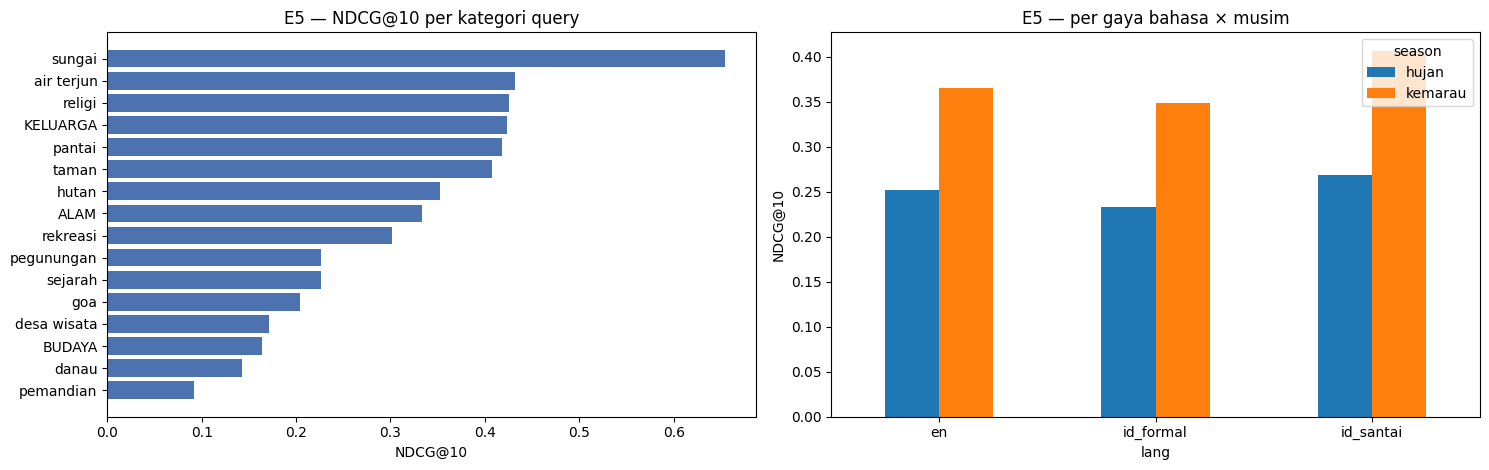

In [14]:
brk = QA[['cat', 'season', 'lang']].copy()
brk['aspek'] = np.where(QA['aspect'] == '-', 'tanpa aspek', 'dengan aspek')
for c in ['NDCG@10', 'MAP@10', 'P@10', 'F1@10', 'ILD@10']:
    brk[c] = perqA[NAME][c]
for col in ['lang', 'season', 'aspek']:
    print(f'\n{NAME} per {col}'); display(brk.groupby(col)[['NDCG@10', 'MAP@10', 'P@10', 'F1@10', 'ILD@10']].mean().round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
by_cat = brk.groupby('cat')['NDCG@10'].mean().sort_values()
ax[0].barh(by_cat.index, by_cat.values, color=MODEL['color']); ax[0].set_xlabel('NDCG@10')
ax[0].set_title(f'{NAME} — NDCG@10 per kategori query')
brk.pivot_table(index='lang', columns='season', values='NDCG@10').plot.bar(ax=ax[1], rot=0)
ax[1].set_ylabel('NDCG@10'); ax[1].set_title(f'{NAME} — per gaya bahasa × musim')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_{tag}_rincian.png', dpi=300); plt.show()

## 8. Evaluasi — Protokol B (known-item, leave-one-review-out)

In [15]:
perqB = {NAME: evaluate(S_B, RELB)}
tabB = metric_table(perqB[NAME], COLS_B + ['ILD@10', 'Novelty@10'])
tabB.loc['Coverage@10'] = [coverage(S_B), np.nan, np.nan]
print(f'{NAME} + cosine — Protokol B ({len(QB_)} query known-item)')
display(tabB.round(4))
tabB.to_csv(f'{OUT_DIR}/hasil_{tag}_protokolB.csv')

E5 + cosine — Protokol B (3942 query known-item)


,nilai,CI95_low,CI95_high
MRR@10,0.3802,0.3665,0.3932
Hit@1,0.2927,0.2788,0.3067
Hit@5,0.4934,0.4779,0.5081
Hit@10,0.5878,0.5720,0.6027
NDCG@10,0.4295,0.4163,0.4422
ILD@10,0.6361,0.6272,0.6453
Novelty@10,7.1311,7.1216,7.1410
Coverage@10,0.9420,NaN,NaN


## 8a. Evaluasi — Protokol C (query uji skripsi)
Query S1 dan S2 dari skripsi, masing-masing pada konteks musim asli dan variasinya. Pada model tunggal, teks query yang sama selalu menghasilkan **ranking yang sama** di semua konteks; yang berubah hanya himpunan destinasi relevan (destinasi tidak cocok musim hujan menjadi tidak relevan). Penyesuaian terhadap musim hanya bisa dilakukan dengan filter keras (baris `+ filter musim keras`) — bandingkan dengan adaptive fusion di notebook 3.

In [16]:
def top10_relevansi(S_dict, i, k=10):
    """Tabel top-k untuk query ke-i; ✓ = relevan, ✓✓ = relevan + aspek kuat, ✗ = tidak relevan."""
    mark = {0: '✗', 1: '✓', 2: '✓✓'}
    return pd.DataFrame({m: [f'{dest.destinasi[d]} {mark[int(RELC[i, d])]}' for d in topk_idx(S[i:i + 1], k)[0]]
                         for m, S in S_dict.items()}, index=range(1, k + 1))

h = (QC['season'] == 'hujan').values
S_C_filter = S_C.copy(); S_C_filter[h] = np.where(NOT_RAIN, -np.inf, S_C_filter[h])
perqC = {f'{NAME} (top-5, default)': evaluate(S_C, RELC), f'{NAME} + filter musim keras': evaluate(S_C_filter, RELC)}
perqC[f'{NAME} (top-5, default)']['SVR@10'] = season_violation(S_C, QC['season'])
perqC[f'{NAME} + filter musim keras']['SVR@10'] = season_violation(S_C_filter, QC['season'])

COLS_C = ['P@5', 'P@10', 'R@10', 'F1@10', 'MAP@10', 'MRR@10', 'NDCG@10', 'ILD@10', 'Novelty@10', 'SVR@10']
tabC = pd.concat([QC[['qid', 'status', 'n_rel']].assign(sistem=m, **{c: v[c] for c in COLS_C}) for m, v in perqC.items()],
                 ignore_index=True)
print(f'{NAME} + cosine — Protokol C (query uji skripsi)')
display(tabC.round(4))
print('Rata-rata:'); display(tabC.groupby('sistem', sort=False)[COLS_C].mean().round(4))
tabC.to_csv(f'{OUT_DIR}/hasil_{tag}_protokolC.csv', index=False)

for i in QC.index[QC.status == 'asli skripsi']:
    print(f"\n{QC.qid[i]} (konteks {QC.season[i]}): {QC.text[i]}")
    display(top10_relevansi({f'{NAME} + cosine': S_C}, i))

E5 + cosine — Protokol C (query uji skripsi)


,qid,status,n_rel,sistem,P@5,P@10,R@10,F1@10,MAP@10,MRR@10,NDCG@10,ILD@10,Novelty@10,SVR@10
0,S1-none,asli skripsi,129,"E5 (top-5, default)",1.0,0.9,0.0698,0.1295,0.9000,1.0,0.9364,0.6444,7.0132,NaN
1,S1-kemarau,variasi musim,129,"E5 (top-5, default)",1.0,0.9,0.0698,0.1295,0.9000,1.0,0.9364,0.6444,7.0132,NaN
2,S1-hujan,variasi musim,52,"E5 (top-5, default)",0.2,0.2,0.0385,0.0645,0.0786,0.5,0.2122,0.6444,7.0132,0.8
3,S2-none,variasi musim,24,"E5 (top-5, default)",0.8,0.6,0.2500,0.3529,0.4864,1.0,0.4802,0.6444,7.1982,NaN
4,S2-kemarau,asli skripsi,24,"E5 (top-5, default)",0.8,0.6,0.2500,0.3529,0.4864,1.0,0.4802,0.6444,7.1982,NaN
5,S2-hujan,variasi musim,15,"E5 (top-5, default)",0.4,0.3,0.2000,0.2400,0.1300,0.5,0.2973,0.6444,7.1982,0.5
6,S1-none,asli skripsi,129,E5 + filter musim keras,1.0,0.9,0.0698,0.1295,0.9000,1.0,0.9364,0.6444,7.0132,NaN
7,S1-kemarau,variasi musim,129,E5 + filter musim keras,1.0,0.9,0.0698,0.1295,0.9000,1.0,0.9364,0.6444,7.0132,NaN
8,S1-hujan,variasi musim,52,E5 + filter musim keras,1.0,0.8,0.1538,0.2581,0.7764,1.0,0.8630,0.8667,6.9801,0.0
9,S2-none,variasi musim,24,E5 + filter musim keras,0.8,0.6,0.2500,0.3529,0.4864,1.0,0.4802,0.6444,7.1982,NaN


Rata-rata:


,P@5,P@10,R@10,F1@10,MAP@10,MRR@10,NDCG@10,ILD@10,Novelty@10,SVR@10
sistem,,,,,,,,,,
"E5 (top-5, default)",0.7000,0.5833,0.1463,0.2116,0.4969,0.8333,0.5571,0.6444,7.1057,0.65
E5 + filter musim keras,0.8667,0.7500,0.2100,0.2972,0.6834,1.0000,0.7302,0.6630,7.1644,0.00



S1-none (konteks none): Saya ingin wisata alam dengan pemandangan indah dan suasana tenang.


,E5 + cosine
1,Taman Wisata Genilangit ✓✓
2,Kawah Ijen ✓✓
3,Buki Teletubies ✓✓
4,Negeri Atas Angin ✓✓
5,Air Terjun Nglirip ✓✓
6,Puncak Ratu ✓✓
7,Gunung Kelud ✓✓
8,Wisata Wonosalam ✓✓
9,Kebunteh Sirahkencong ✓✓
10,Selecta ✗



S2-kemarau (konteks kemarau): Air terjun dengan suasana sejuk dan tenang, pemandangan alami, aliran air jernih, cocok untuk relaksasi dan menikmati udara segar.


,E5 + cosine
1,Air Terjun Mandakaripuna ✓
2,Sedudo ✓✓
3,Jamus ✗
4,Air Dolo ✓✓
5,Air Terjun Nglirip ✓✓
6,Grogoland ✗
7,Air terjun Dlundung ✓
8,Kebunteh Sirahkencong ✗
9,Telaga Ngabel ✗
10,Air Terjun Roro Kuning ✓✓


## 8b. Evaluasi — Protokol D (query uji berbasis literatur)
Query naratif gaya forum (D1, mengikuti POINTREC/TourismQA) dan query persona × kompleksitas (D2, mengikuti SynthTRIPs); musim tersirat dari **bulan** perjalanan. Ditampilkan juga kinerja per tingkat kompleksitas dan **ketahanan terhadap teks persona** (selisih NDCG@10 versi persona − vanilla pada filter yang sama).

In [17]:
perqD = {f'{NAME} (top-5, default)': evaluate(S_D, RELD)}
perqD[f'{NAME} (top-5, default)']['SVR@10'] = season_violation(S_D, QD['season'])
pD = perqD[f'{NAME} (top-5, default)']
tabD = metric_table(pD, COLS_ACC_A + COLS_BEYOND)
tabD.loc['Coverage@10'] = [coverage(S_D), np.nan, np.nan]
print(f'{NAME} + cosine — Protokol D ({len(QD)} query)')
display(tabD.round(4))
tabD.to_csv(f'{OUT_DIR}/hasil_{tag}_protokolD.csv')

brkD = QD[['jenis', 'kompleksitas', 'season', 'lang']].copy()
for c in ['NDCG@10', 'P@10', 'MAP@10', 'SVR@10']:
    brkD[c] = pD[c]
for col in ['jenis', 'kompleksitas', 'season']:
    print(f'\n{NAME} per {col}'); display(brkD.groupby(col)[['NDCG@10', 'P@10', 'MAP@10', 'SVR@10']].mean().round(4))

pv = QD[QD.jenis.isin(['vanilla', 'persona'])].reset_index()
x = pv.assign(v=pD['NDCG@10'][pv['index']]).pivot_table(index='cfg', columns='jenis', values='v')
d = (x['persona'] - x['vanilla']).values
p = stats.wilcoxon(x['persona'], x['vanilla'], zero_method='zsplit').pvalue if np.std(d) > 0 else 1.0
print(f'Ketahanan teks persona: Δ NDCG@10 (persona − vanilla) = {d.mean():+.4f} | p Wilcoxon = {p:.4f} | n pasangan = {len(d)}')

E5 + cosine — Protokol D (260 query)


,nilai,CI95_low,CI95_high
P@5,0.4338,0.3869,0.4777
P@10,0.3915,0.3504,0.4285
R@10,0.2524,0.2275,0.2765
F1@10,0.2789,0.2525,0.3045
MAP@10,0.3261,0.2871,0.3640
MRR@10,0.5877,0.5372,0.6367
NDCG@5,0.4284,0.3841,0.4705
NDCG@10,0.4164,0.3767,0.4524
Hit@10,0.7923,0.7385,0.8385
ILD@10,0.5738,0.5393,0.6102



E5 per jenis


,NDCG@10,P@10,MAP@10,SVR@10
jenis,,,,
naratif,0.4573,0.4350,0.3803,0.4000
persona,0.4648,0.4167,0.3604,0.5212
vanilla,0.3612,0.3592,0.2827,0.5273



E5 per kompleksitas


,NDCG@10,P@10,MAP@10,SVR@10
kompleksitas,,,,
-,0.4573,0.4350,0.3803,0.4000
berkelanjutan,0.0613,0.0317,0.0338,0.5542
mudah,0.6115,0.5767,0.4788,NaN
sedang,0.5432,0.5167,0.4244,0.4500
sulit,0.4362,0.4267,0.3494,0.5700



E5 per season


,NDCG@10,P@10,MAP@10,SVR@10
season,,,,
hujan,0.2154,0.1973,0.1290,0.5123
kemarau,0.4351,0.4047,0.3561,NaN
none,0.5458,0.5208,0.4429,NaN


Ketahanan teks persona: Δ NDCG@10 (persona − vanilla) = +0.1036 | p Wilcoxon = 0.0000 | n pasangan = 120


## 8c. Analisis sensitivitas
- **Agregasi ulasan→destinasi**: top-1 (max), top-3, top-5 (default), top-10, centroid.
- **Prefiks** (khusus model yang memakai prefiks seperti E5): dengan vs tanpa `query:`/`passage:`.
- **Filter musim keras** (seperti skripsi): untuk query musim hujan, destinasi berlabel `Kemarau` saja dibuang dari ranking — memperlihatkan seberapa banyak kinerja berasal dari label musim, bukan dari pemahaman teks.

Setiap varian diuji berpasangan terhadap konfigurasi default (Wilcoxon + koreksi Holm).

In [18]:
def holm(p):
    p = np.asarray(p); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for r, i in enumerate(o):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(1, run)
    return adj

def significance(perq, ref, metric):
    rows = []
    a = np.nan_to_num(perq[ref][metric])
    for m in perq:
        if m == ref:
            continue
        b_ = np.nan_to_num(perq[m][metric]); d = b_ - a
        try:
            w_p = stats.wilcoxon(a, b_, zero_method='zsplit').pvalue if d.std() > 0 else 1.0
        except ValueError:
            w_p = 1.0
        rows.append(dict(varian=m, rata2=b_.mean(), delta_vs_default=d.mean(),
                         win=(d > 1e-9).mean(), tie=(np.abs(d) <= 1e-9).mean(), loss=(d < -1e-9).mean(), p_wilcoxon=w_p))
    out = pd.DataFrame(rows)
    out['p_holm'] = holm(out['p_wilcoxon'].values)
    out['signifikan (α=0.05)'] = out['p_holm'] < 0.05
    return out

def rain_filter(S, seasons):
    S = S.copy(); h = np.asarray(seasons) == 'hujan'
    S[h] = np.where(NOT_RAIN, -np.inf, S[h])
    return S

DEF = f'{NAME} (top-5, default)'
varA, varB = {DEF: S_A}, {DEF: S_B}
for m in [1, 3, 10]:
    varA[f'{NAME} top-{m}'] = dense_scores(QA_emb, R, topm=m)
    varB[f'{NAME} top-{m}'] = dense_scores(QB_emb, R, EXCL_B, topm=m)
varA[f'{NAME} centroid'] = centroid_scores(QA_emb, R)
varB[f'{NAME} centroid'] = centroid_scores(QB_emb, R, EXCL_B)
if ABLASI_PREFIX:
    varA[f'{NAME} tanpa prefiks'] = dense_scores(QA_np, R_np)
    varB[f'{NAME} tanpa prefiks'] = dense_scores(QB_np, R_np, EXCL_B)
varA[f'{NAME} + filter musim keras'] = rain_filter(S_A, QA['season'])

perq_varA = {m: evaluate(S, RELA) for m, S in varA.items()}
perq_varB = {m: evaluate(S, RELB) for m, S in varB.items()}
for m, S in varA.items():
    perq_varA[m]['SVR@10'] = season_violation(S, QA['season'])

print('Protokol A'); display(summarize(perq_varA, ['P@10', 'F1@10', 'MAP@10', 'NDCG@10'] + COLS_BEYOND).round(4))
display(significance(perq_varA, DEF, 'NDCG@10').round(4))
print('\nProtokol B'); display(summarize(perq_varB, COLS_B).round(4))
display(significance(perq_varB, DEF, 'MRR@10').round(4))

Protokol A


,P@10,F1@10,MAP@10,NDCG@10,ILD@10,Novelty@10,SVR@10
"E5 (top-5, default)",0.2943,0.2154,0.2239,0.3143,0.7544,6.9960,0.5020
E5 top-1,0.2389,0.1720,0.1721,0.2532,0.8136,7.3305,0.4854
E5 top-3,0.2814,0.2061,0.2140,0.3047,0.7723,7.0938,0.4941
E5 top-10,0.3005,0.2186,0.2249,0.3160,0.7470,6.8778,0.4968
E5 centroid,0.3207,0.2367,0.2431,0.3083,0.7413,8.3386,0.5526
E5 tanpa prefiks,0.2861,0.2060,0.2145,0.2958,0.7813,6.9269,0.5114
E5 + filter musim keras,0.3698,0.2734,0.3064,0.3962,0.7811,7.0415,0.0000


,varian,rata2,delta_vs_default,win,tie,loss,p_wilcoxon,p_holm,signifikan (α=0.05)
0,E5 top-1,0.2532,-0.0612,0.2712,0.1207,0.6081,0.0000,0.0000,True
1,E5 top-3,0.3047,-0.0096,0.3405,0.2007,0.4588,0.0000,0.0001,True
2,E5 top-10,0.3160,0.0017,0.4277,0.2091,0.3632,0.0403,0.0806,False
3,E5 centroid,0.3083,-0.0060,0.4588,0.0633,0.4779,0.3502,0.3502,False
4,E5 tanpa prefiks,0.2958,-0.0186,0.3835,0.1410,0.4755,0.0002,0.0005,True
5,E5 + filter musim keras,0.3962,0.0818,0.4217,0.5783,0.0000,0.0000,0.0000,True



Protokol B


,MRR@10,Hit@1,Hit@5,Hit@10,NDCG@10
"E5 (top-5, default)",0.3802,0.2927,0.4934,0.5878,0.4295
E5 top-1,0.3269,0.2405,0.4434,0.5424,0.3779
E5 top-3,0.3750,0.2869,0.4909,0.5878,0.4255
E5 top-10,0.3698,0.2846,0.4792,0.5728,0.4180
E5 centroid,0.3431,0.2516,0.4622,0.5708,0.3970
E5 tanpa prefiks,0.4247,0.3399,0.5365,0.6190,0.4710


,varian,rata2,delta_vs_default,win,tie,loss,p_wilcoxon,p_holm,signifikan (α=0.05)
0,E5 top-1,0.3269,-0.0533,0.1131,0.6162,0.2707,0.0000,0.0000,True
1,E5 top-3,0.3750,-0.0052,0.0972,0.7717,0.1312,0.0006,0.0013,True
2,E5 top-10,0.3698,-0.0104,0.1096,0.7572,0.1332,0.0101,0.0101,True
3,E5 centroid,0.3431,-0.0371,0.2293,0.4937,0.2770,0.0000,0.0000,True
4,E5 tanpa prefiks,0.4247,0.0445,0.2255,0.6367,0.1377,0.0000,0.0000,True


## 9. Sistem rekomendasi (inferensi) + studi kasus
`rekomendasi(query, musim)` mengembalikan top-k destinasi beserta **ulasan bukti** (ulasan dengan cosine tertinggi) sebagai penjelasan. Pada model tunggal, konteks musim hanya dapat dipakai sebagai **filter** (`filter_musim=True`), bukan sebagai pembobot seperti pada adaptive fusion (notebook 3).

In [19]:
R_t = torch.from_numpy(R).to(DEVICE, DTYPE)

def rekomendasi(query, musim='hujan', k=10, filter_musim=False):
    t0 = time.time()
    q = encode(enc, [query], MODEL['q_prefix'])
    s = dense_scores(q, R)[0]
    if filter_musim and musim == 'hujan':
        s = np.where(NOT_RAIN, -np.inf, s)
    top = np.argsort(-s, kind='stable')[:k]
    latency = time.time() - t0
    sim = (R_t @ torch.from_numpy(q[0]).to(DEVICE, DTYPE)).float().cpu().numpy()
    bukti = [df['text'].iat[OFFSETS[d] + int(np.argmax(sim[OFFSETS[d]:OFFSETS[d + 1]]))][:160] for d in top]
    out = dest.iloc[top][['destinasi', 'wisata', 'musim', 'rating_mean']].assign(
        skor_cosine=s[top].round(4), ulasan_bukti=bukti).reset_index(drop=True)
    out.index += 1
    print(f'[{NAME}] Query: "{query}" | musim: {musim} | filter musim: {filter_musim} | latensi {latency * 1000:.0f} ms')
    return out

display(rekomendasi('wisata alam saat musim hujan', 'hujan'))
display(rekomendasi('wisata alam saat musim hujan', 'hujan', filter_musim=True))
display(rekomendasi('pantai yang bersih dan cocok untuk keluarga', 'kemarau'))
display(rekomendasi('quiet waterfall with cool air', 'none'))

q = 'wisata alam saat musim hujan'
rel_q = (dest['wisata'].isin(CATS['ALAM'][0]) & dest['cocok_hujan']).values
top = topk_idx(dense_scores(encode(enc, [q], MODEL['q_prefix']), R), 10)[0]
print(f'Studi kasus "{q}": relevan@10 = {int(rel_q[top].sum())}/10 | '
      f'tidak cocok musim hujan @10 = {int(NOT_RAIN[top].sum())}')

[E5] Query: "wisata alam saat musim hujan" | musim: hujan | filter musim: False | latensi 218 ms


,destinasi,wisata,musim,rating_mean,skor_cosine,ulasan_bukti
1,Taman Rajekwesi,taman,Kemarau & Penghujan,4.370479,0.8668,"Musim penghujan ke taman emang agak gambling sih, takut kena hujan tiba-tiba. Tapi saya udah beberapa kali ke Rajekw..."
2,Waduk Pacal,danau/waduk,Kemarau,4.371212,0.8668,"Tempat ini paling indah dikunjungi pas musim penghujan. Airnya penuh, sekitar waduk jadi hijau semua, dan udaranya s..."
3,Air Terjun Mandakaripuna,air terjun,Kemarau,4.014257,0.8665,"Wisata alam air terjun yg cukup dikenal masyarakat Jatim. Sekedar saran saja, menurut saya. Waktu terbaik kesana ada..."
4,Air Terjun Nglirip,air terjun,Kemarau,4.602740,0.8646,Air terjun yang eksotik tapi pastikan waktu berkunjung jika waktu penghujan maka airnya tidak sebening yg dibayangka...
5,Taman Nasional Baluran,hutan/perkebunan,Kemarau & Penghujan,4.641444,0.8627,"Africa van java. Pas kemarau ataupun pas penghujan, sama2 bagus."
6,Air Terjun Kedung Maor,air terjun,Kemarau,4.500000,0.8626,"Waktu musim hujan air terjunnya lebih rame dan bunyinya kenceng, puas lihatnya. Tapi mending pakai sandal gunung bia..."
7,Sedudo,air terjun,Kemarau & Penghujan,4.603531,0.8619,Pengalaman yang menyenangkanSayang datang pas hujan
8,Buki Teletubies,pegunungan,Kemarau,4.746006,0.8618,Berkunjung pada musim hujan jadi tidak maksimal menikmati pemandangannya
9,Wana Wisata Grape,rekreasi/edukasi,Kemarau,4.253521,0.8606,Tempat wisata alam
10,Kebunteh Sirahkencong,hutan/perkebunan,Kemarau,4.629397,0.8604,Tempat Liburan Menyenangkan usahakan suasana ke sini cerah karena jika hujan ke air terjun jalannya licin


[E5] Query: "wisata alam saat musim hujan" | musim: hujan | filter musim: True | latensi 102 ms


,destinasi,wisata,musim,rating_mean,skor_cosine,ulasan_bukti
1,Taman Rajekwesi,taman,Kemarau & Penghujan,4.370479,0.8668,"Musim penghujan ke taman emang agak gambling sih, takut kena hujan tiba-tiba. Tapi saya udah beberapa kali ke Rajekw..."
2,Taman Nasional Baluran,hutan/perkebunan,Kemarau & Penghujan,4.641444,0.8627,"Africa van java. Pas kemarau ataupun pas penghujan, sama2 bagus."
3,Sedudo,air terjun,Kemarau & Penghujan,4.603531,0.8619,Pengalaman yang menyenangkanSayang datang pas hujan
4,Sungai Maron,sungai,Kemarau & Penghujan,4.727802,0.8602,"menyusuri sungai menggunakan kapal, tempatnya instagramble, tapi sayang kesananya abis hujan jadi sungainya keruh"
5,Taman Safari Prigen,rekreasi/edukasi,Kemarau & Penghujan,4.524966,0.8600,Wahana banyak tutup saat hujan
6,Cimori,rekreasi/edukasi,Kemarau & Penghujan,4.526316,0.8591,Kesana pas hujan. Tapi tetep seru sekali. Wahananya jg makin banyak. Bersih jg.
7,Kawah Wurung,pegunungan,Kemarau & Penghujan,4.644836,0.8583,"Lebih suka ke Kawah Wurung saat musim hujan, sehingga kenampakan kawahnya hijau. Pemandangan sepanjang perjalanan me..."
8,Coban Rondo,air terjun,Kemarau & Penghujan,4.723810,0.8573,"Wisata alam yang tenang nyaman dan pemandangan luar biasa. Cocok untuk menenangkan diri, ga bisa langsung berenang d..."
9,Air Dolo,air terjun,Kemarau & Penghujan,4.517857,0.8563,Wisata air terjun
10,Coban Rais,air terjun,Kemarau & Penghujan,3.993274,0.8563,Hati2 klo musim hujan.... Tkut longsor dan banjir klo mw k air terjun... Jln e pnjang klo k air terjun


[E5] Query: "pantai yang bersih dan cocok untuk keluarga" | musim: kemarau | filter musim: False | latensi 94 ms


,destinasi,wisata,musim,rating_mean,skor_cosine,ulasan_bukti
1,Pantai Mutiara,pantai,Kemarau,4.475236,0.9115,Pantai cocok buat kluarga
2,Pantai Ngliyep,pantai,Kemarau,4.623870,0.9037,Pantainya bagus bersih healing bareng keluarga cocok banget
3,Pantai Srau,pantai,Kemarau,4.702970,0.9037,Pantai nyaman dan bersih rekomen bgt bwt ngacara
4,Pantai Pasir Putih,pantai,Kemarau & Penghujan,4.391089,0.9028,Pantai cantik nan bersih layak buat santai bersama keluarga sambil menikmati senja
5,Pantai Watuulo,pantai,Kemarau,4.306173,0.9021,Pantai yg cocok u refreshing kluargaTarip murah
6,Pantai Lon Malang,pantai,Kemarau,4.360887,0.9020,"Kerreen, pantai nya bersih, cocok liburan bareng keluarga"
7,Pantai Watu Karang,pantai,Kemarau,4.754508,0.9006,Pantai bersih enak buat bermain anak²
8,Pantai Serang,pantai,Kemarau,4.599034,0.8985,Pantainya bersih dan tertata lumayan rapi
9,Pantai Telengria,pantai,Kemarau,4.408736,0.8982,Pantai bersih bgt nyaman juga buat santai
10,Pantai Prigi,pantai,Kemarau & Penghujan,4.467857,0.8981,pantai ramai pengunjung cocok buat keluarga


[E5] Query: "quiet waterfall with cool air" | musim: none | filter musim: False | latensi 94 ms


,destinasi,wisata,musim,rating_mean,skor_cosine,ulasan_bukti
1,Sedudo,air terjun,Kemarau & Penghujan,4.603531,0.8574,Air terjun yang sejuk dan indah
2,Coban Rondo,air terjun,Kemarau & Penghujan,4.723810,0.8568,"Nice and peaceful area, the waterfall wist impressive to see, it is nice to stand in the little river coming from th..."
3,Air Terjun Mandakaripuna,air terjun,Kemarau,4.014257,0.8562,"Gorgeous waterfall, serene environment, advise to bring raincoat, also a guide will be very helpful."
4,Air Terjun Toroan,air terjun,Kemarau & Penghujan,4.428191,0.8541,"Good Waterfall, short trekking and good for chillin"
5,Air terjun Dlundung,air terjun,Kemarau,4.446154,0.8467,Beautiful waterfall landscape
6,Kebunteh Sirahkencong,hutan/perkebunan,Kemarau,4.629397,0.8451,Tempat santai sambil menikmati udara sejuk di daerah blitar
7,Air Terjuntumpaksewu,air terjun,Kemarau,4.762749,0.8438,Beautiful waterfall but with the very amount of turist this waterfall falling his majestic magic
8,Air Terjun Nglirip,air terjun,Kemarau,4.602740,0.8435,"Nglirip waterfall Tuban,,, mantap jiwa.Airnya warna hijau bersih"
9,Air Terjun Roro Kuning,air terjun,Kemarau & Penghujan,4.209040,0.8422,"Good waterfall with cool weather, but maybe needs a lot of improvement on the access and facilities."
10,Telaga Ngabel,danau/waduk,Kemarau & Penghujan,4.549528,0.8406,Udaranya sejukSambil ngopi mantap


Studi kasus "wisata alam saat musim hujan": relevan@10 = 2/10 | tidak cocok musim hujan @10 = 7


## 10. Simpan hasil
`metrik_per_query_e5.csv` dipakai notebook 3 untuk memastikan angka model tunggal identik dengan yang dihitung di sana. Perbandingan resmi **E5 vs adaptive fusion** (uji signifikansi berpasangan) ada di notebook 3, Bagian 9 & 11.

In [20]:
def perq_frame(perq, protokol):
    return pd.concat([pd.DataFrame({'protokol': protokol, 'qid': np.arange(len(v['NDCG@10'])), 'metode': m, **v})
                      for m, v in perq.items()], ignore_index=True)
pd.concat([perq_frame(perq_varA, 'A'), perq_frame(perq_varB, 'B'), perq_frame(perqC, 'C'), perq_frame(perqD, 'D')]).to_csv(f'{OUT_DIR}/metrik_per_query_{tag}.csv', index=False)

summary = {
    'sistem': f'{NAME} + cosine', 'model': MODEL['hf'], 'mock': MOCK, 'n_ulasan': int(N), 'n_destinasi': int(D),
    'n_query_A': int(len(QA)), 'n_query_B': int(len(QB_)), 'topm': CFG['topm'],
    'protokolA': tabA['nilai'].round(4).to_dict(), 'protokolB': tabB['nilai'].round(4).to_dict(),
    'protokolC': tabC.groupby('sistem', sort=False)[['P@10', 'MAP@10', 'NDCG@10', 'SVR@10']].mean().round(4).to_dict('index'),
    'protokolD': tabD['nilai'].round(4).to_dict(),
}
with open(f'{OUT_DIR}/ringkasan_{tag}.json', 'w', encoding='utf-8') as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
for name, tab in [(f'tabel_{tag}_protokolA', tabA), (f'tabel_{tag}_protokolB', tabB)]:
    try:
        with open(f'{OUT_DIR}/{name}.tex', 'w', encoding='utf-8') as f:
            f.write(tab.round(4).to_latex(float_format='%.4f'))
    except Exception as e:
        print('LaTeX dilewati:', e)
print(json.dumps(summary, indent=2, ensure_ascii=False))
print('\nFile keluaran:', sorted(os.listdir(OUT_DIR)))

{
  "sistem": "E5 + cosine",
  "model": "intfloat/multilingual-e5-large",
  "mock": false,
  "n_ulasan": 67283,
  "n_destinasi": 207,
  "n_query_A": 837,
  "n_query_B": 3942,
  "topm": 5,
  "protokolA": {
    "P@5": 0.3223,
    "P@10": 0.2943,
    "R@10": 0.2313,
    "F1@10": 0.2154,
    "MAP@10": 0.2239,
    "MRR@10": 0.5451,
    "NDCG@5": 0.2987,
    "NDCG@10": 0.3143,
    "Hit@10": 0.8746,
    "ILD@10": 0.7544,
    "Novelty@10": 6.996,
    "SVR@10": 0.502,
    "Coverage@10": 0.6812
  },
  "protokolB": {
    "MRR@10": 0.3802,
    "Hit@1": 0.2927,
    "Hit@5": 0.4934,
    "Hit@10": 0.5878,
    "NDCG@10": 0.4295,
    "ILD@10": 0.6361,
    "Novelty@10": 7.1311,
    "Coverage@10": 0.942
  },
  "protokolC": {
    "E5 (top-5, default)": {
      "P@10": 0.5833,
      "MAP@10": 0.4969,
      "NDCG@10": 0.5571,
      "SVR@10": 0.65
    },
    "E5 + filter musim keras": {
      "P@10": 0.75,
      "MAP@10": 0.6834,
      "NDCG@10": 0.7302,
      "SVR@10": 0.0
    }
  },
  "protokolD": {
    "P